In [1]:
def bond_price(face, coupon_rate, ytm, years, freq=2):
    n = int(round(years * freq))
    c = face * coupon_rate / freq
    y = ytm / freq
    pv_coupons = sum(c / (1 + y) ** t for t in range(1, n + 1))
    pv_face = face / (1 + y) ** n
    return pv_coupons + pv_face


def durations(face, coupon_rate, ytm, years, freq=2):
    n = int(round(years * freq))
    c = face * coupon_rate / freq
    y = ytm / freq
    weighted_sum = 0
    price = 0
    for t in range(1, n + 1):
        cash_flow = c
        if t == n:
            cash_flow = c + face
        pv = cash_flow / (1 + y) ** t
        price = price + pv
        weighted_sum = weighted_sum + t * pv
    macaulay = weighted_sum / price / freq
    modified = macaulay / (1 + y)
    return macaulay, modified


def convexity(face, coupon_rate, ytm, years, freq=2):
    n = int(round(years * freq))
    c = face * coupon_rate / freq
    y = ytm / freq
    total = 0
    price = 0
    for t in range(1, n + 1):
        cash_flow = c
        if t == n:
            cash_flow = c + face
        pv = cash_flow / (1 + y) ** t
        price = price + pv
        total = total + t * (t + 1) * pv
    conv_periods = total / price / (1 + y) ** 2
    return conv_periods / freq ** 2          # convert to annual terms


def sensitivity2(face, coupon_rate, ytm, years, shock_bps, freq=2):
    base = bond_price(face, coupon_rate, ytm, years, freq)
    mac, mod = durations(face, coupon_rate, ytm, years, freq)
    conv = convexity(face, coupon_rate, ytm, years, freq)
    dy = shock_bps / 10000
    est_dur = base * (1 - mod * dy)
    est_conv = base * (1 - mod * dy + 0.5 * conv * dy ** 2)
    actual = bond_price(face, coupon_rate, ytm + dy, years, freq)
    return est_dur, est_conv, actual

In [2]:
print("Convexity:", convexity(1000, 0.08, 0.10, 5))

Convexity: 19.573560569955475


In [3]:
c0 = convexity(1000, 0.0, 0.10, 5)
print(c0)
assert abs(c0 - 10 * 11 / 1.05 ** 2 / 4) < 1e-9
print("Zero-coupon convexity test passed")

24.94331065759637
Zero-coupon convexity test passed


In [4]:
import pandas as pd

rows = []
for bps in [-200, -100, -50, 50, 100, 200]:
    ed, ec, act = sensitivity2(1000, 0.08, 0.10, 5, bps)
    rows.append([bps, ed, ec, act, ed - act, ec - act])

table = pd.DataFrame(rows, columns=["Shock (bps)", "Duration only", "Dur + Conv", "Actual", "Err (dur)", "Err (dur+conv)"])
print(table.round(3))

for r in rows:
    assert abs(r[5]) < abs(r[4])
print("Convexity improves every estimate")

   Shock (bps)  Duration only  Dur + Conv    Actual  Err (dur)  Err (dur+conv)
0         -200        996.250     999.863  1000.000     -3.750          -0.137
1         -100        959.516     960.419   960.436     -0.920          -0.017
2          -50        941.150     941.375   941.377     -0.228          -0.002
3           50        904.416     904.642   904.639     -0.224           0.002
4          100        886.049     886.952   886.936     -0.887           0.016
5          200        849.315     852.928   852.798     -3.483           0.129
Convexity improves every estimate


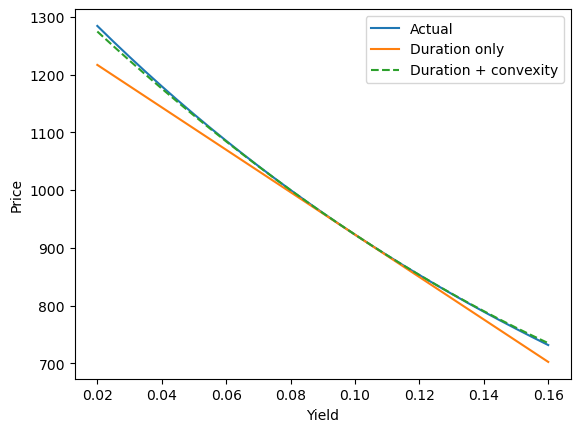

In [5]:
import matplotlib.pyplot as plt

yields = [i / 1000 for i in range(20, 161, 5)]
actual = [bond_price(1000, 0.08, y, 5) for y in yields]
dur_line = []
conv_line = []
for y in yields:
    bps = (y - 0.10) * 10000
    ed, ec, _ = sensitivity2(1000, 0.08, 0.10, 5, bps)
    dur_line.append(ed)
    conv_line.append(ec)

plt.plot(yields, actual, label="Actual")
plt.plot(yields, dur_line, label="Duration only")
plt.plot(yields, conv_line, "--", label="Duration + convexity")
plt.xlabel("Yield")
plt.ylabel("Price")
plt.legend()
plt.show()